In [3]:
#OneR
!pip install scikit-learn pandas
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import KBinsDiscretizer
data = load_breast_cancer(as_frame=True)
df = data.frame.dropna().drop_duplicates()
X, y = df.drop(columns="target"), df["target"]

disc = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile")
Xd = pd.DataFrame(disc.fit_transform(X), columns=X.columns).astype(int)
X_train, X_test, y_train, y_test = train_test_split(Xd, y, test_size=0.2, random_state=42, stratify=y)
best_feature, best_rules, best_acc = None, None, -1
for col in X_train.columns:
 rules = X_train.assign(target=y_train.values).groupby(col)["target"].agg(lambda s: s.mode().iloc[0]).to_dict()
 pred = X_train[col].map(rules)
 acc = (pred.values == y_train.values).mean()
 if acc > best_acc:
     best_feature, best_rules, best_acc = col, rules, acc
pred = X_test[best_feature].map(best_rules).fillna(y_train.mode().iloc[0]).astype(int)
print("Selected feature:", best_feature)
print("Rules (bin -> class):", best_rules)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Confusion matrix:\\n", confusion_matrix(y_test, pred))

Selected feature: worst radius
Rules (bin -> class): {0: 1, 1: 1, 2: 0}
              precision    recall  f1-score   support

           0       0.92      0.86      0.89        42
           1       0.92      0.96      0.94        72

    accuracy                           0.92       114
   macro avg       0.92      0.91      0.91       114
weighted avg       0.92      0.92      0.92       114

Accuracy: 0.9210526315789473
Confusion matrix:\n [[36  6]
 [ 3 69]]


In [5]:
#Ripper
!pip install wittgenstein scikit-learn pandas
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from wittgenstein import RIPPER
data = load_breast_cancer(as_frame=True)
df = data.frame[["mean radius", "mean texture", "mean smoothness", "target"]].dropna()

for col in ["mean radius", "mean texture", "mean smoothness"]:
 df[col] = pd.qcut(df[col], q=3, labels=["low", "medium", "high"], duplicates="drop").astype(str)
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])
model = RIPPER(random_state=42)
model.fit(train, class_feat="target", pos_class=1)
pred = model.predict(test.drop(columns="target"))
print(model.ruleset_)
print(classification_report(test["target"], pred, zero_division=0))
print("Accuracy:", accuracy_score(test["target"], pred))

  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for wittgenstein: filename=wittgenstein-0.3.5-py3-none-any.whl size=99038 sha256=0aa59c2445b605c5415bca315498ab66f797f8cdcd9e8c3b63f8630f45f3a330
  Stored in directory: c:\users\praja\appdata\local\pip\cache\wheels\ed\c4\1c\36ab0b352b6fc249d4bb154081713e3a42c868994e8aaa74de
Successfully built wittgenstein
[[meanradius=low] V [meanradius=medium^meansmoothness=low] V [meanradius=medium^meantexture=low^meansmoothness=medium] V [meanradius=medium^meantexture=low] V [meanradius=medium^meansmoothness=medium^meantexture=medium] V [meantexture=low^meansmoothness=low] V [meanradius=medium^meantexture=medium]]
              precision    recall  f1-score   support

           0       0.82      0.88      0.85        42
           1       0.93      0.89      0.91        72

    accuracy                           0.89       114
   macro avg       0.87      0.88      0.88       114
we

In [6]:
#rule based classifiers
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
df = load_breast_cancer(as_frame=True).frame.dropna().drop_duplicates()
X, y = df.drop(columns="target"), df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
feature = "mean concave points"
threshold = X_train[feature].median()

left_class = y_train[X_train[feature] <= threshold].mode().iloc[0]
right_class = y_train[X_train[feature] > threshold].mode().iloc[0]
pred = (X_test[feature] > threshold).map({False: left_class, True: right_class}).astype(int)
print(f"IF {feature} > {threshold:.4f} THEN class={right_class} ELSE class={left_class}")
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))

IF mean concave points > 0.0326 THEN class=0 ELSE class=1
              precision    recall  f1-score   support

           0       0.63      0.98      0.77        42
           1       0.98      0.67      0.79        72

    accuracy                           0.78       114
   macro avg       0.81      0.82      0.78       114
weighted avg       0.85      0.78      0.78       114

Accuracy: 0.7807017543859649


In [9]:
%pip install --force-reinstall numpy==1.26.4

  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.17.1 which is incompatible.
pgmpy 1.1.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
streamlit 1.37.1 requires pandas<3,>=1.3.0, but you have pandas 3.0.6 which is incompatible.
streamlit 1.37.1 requires protobuf<6,>=3.20, but you have protobuf 7.34.1 which is incompatible.
streamlit 1.37.1 requires rich<14,>=10.14.0, but you have rich 15.0.0 which is incompatible.


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

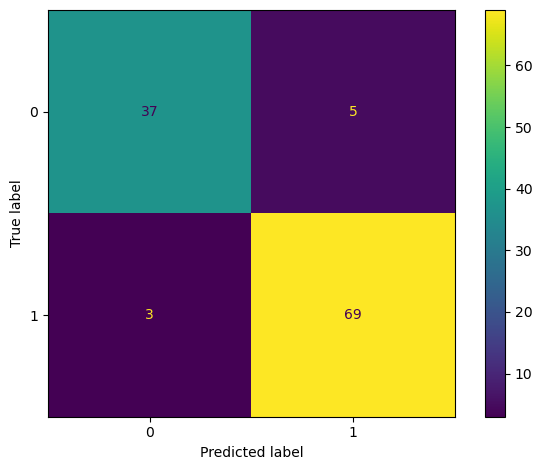

Saved model to nearest_centroid.joblib


In [1]:
#nearest centroid
!pip install scikit-learn pandas matplotlib joblib
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
 ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
from sklearn.base import clone

data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X = df.drop(columns="target")
y = df["target"]

print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y
)
from sklearn.neighbors import NearestCentroid
model = NearestCentroid()
steps = [("scale", StandardScaler()), ("model", model)]
pipe = Pipeline(steps)

search = GridSearchCV(pipe, {"model__metric": ["euclidean", "manhattan"]}, cv=3, scoring="f1_weighted", n_jobs=-1)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_)

pred = best_model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1:", f1_score(y_test, pred, average="weighted", zero_division=0))
print("Confusion matrix:\\n", confusion_matrix(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.tight_layout()
plt.show()

joblib.dump(best_model, "nearest_centroid.joblib")
print("Saved model to nearest_centroid.joblib")